# 1. Mission and use case

Unemployment is a serious challenge in Somaliland/Somalia and across Africa. This project helps labour-market analysts and government planners estimate national unemployment rates when survey data is missing. I focus on the Horn of Africa, while using data from across Africa because many countries face similar employment challenges.

# 2. Download and build the dataset

I download unemployment and 12 economic indicators from the World Bank World Development Indicators API. I join the data by country and year, add each country's African region, and save both the original and cleaned datasets.

In [1]:
from pathlib import Path

import pandas as pd
import requests

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
COUNTRY_CODES = (
    "DZA;AGO;BEN;BWA;BFA;BDI;CPV;CMR;CAF;TCD;COM;COD;COG;CIV;DJI;EGY;GNQ;ERI;"
    "SWZ;ETH;GAB;GMB;GHA;GIN;GNB;KEN;LSO;LBR;LBY;MDG;MWI;MLI;MRT;MUS;MAR;"
    "MOZ;NAM;NER;NGA;RWA;STP;SEN;SYC;SLE;SOM;ZAF;SSD;SDN;TZA;TGO;TUN;UGA;ZMB;ZWE"
)
INDICATORS = {
    "unemployment_rate": "SL.UEM.TOTL.ZS",
    "gdp_growth": "NY.GDP.MKTP.KD.ZG",
    "gdp_per_capita": "NY.GDP.PCAP.CD",
    "inflation": "FP.CPI.TOTL.ZG",
    "labor_force_participation": "SL.TLF.CACT.ZS",
    "population_growth": "SP.POP.GROW",
    "urban_population": "SP.URB.TOTL.IN.ZS",
    "trade_pct_gdp": "NE.TRD.GNFS.ZS",
    "fdi_pct_gdp": "BX.KLT.DINV.WD.GD.ZS",
    "agriculture_pct_gdp": "NV.AGR.TOTL.ZS",
    "industry_pct_gdp": "NV.IND.TOTL.ZS",
    "secondary_enrollment": "SE.SEC.ENRR",
    "life_expectancy": "SP.DYN.LE00.IN",
}
COUNTRY_RENAMES = {
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Somalia, Fed. Rep.": "Somalia",
}
COUNTRY_SUB_REGIONS = {
    "Algeria": "North", "Angola": "Central", "Benin": "West",
    "Botswana": "Southern", "Burkina Faso": "West", "Burundi": "East",
    "Cabo Verde": "West", "Cameroon": "Central",
    "Central African Republic": "Central", "Chad": "Central",
    "Comoros": "East", "Congo, Dem. Rep.": "Central", "Congo, Rep.": "Central",
    "Cote d'Ivoire": "West", "Djibouti": "East", "Egypt": "North",
    "Equatorial Guinea": "Central", "Eritrea": "East", "Eswatini": "Southern",
    "Ethiopia": "East", "Gabon": "Central", "Gambia": "West", "Ghana": "West",
    "Guinea": "West", "Guinea-Bissau": "West", "Kenya": "East",
    "Lesotho": "Southern", "Liberia": "West", "Libya": "North",
    "Madagascar": "East", "Malawi": "East", "Mali": "West",
    "Mauritania": "West", "Mauritius": "East", "Morocco": "North",
    "Mozambique": "East", "Namibia": "Southern", "Niger": "West",
    "Nigeria": "West", "Rwanda": "East", "Sao Tome and Principe": "Central",
    "Senegal": "West", "Seychelles": "East", "Sierra Leone": "West",
    "Somalia": "East", "South Africa": "Southern", "South Sudan": "East",
    "Sudan": "North", "Tanzania": "East", "Togo": "West", "Tunisia": "North",
    "Uganda": "East", "Zambia": "East", "Zimbabwe": "East",
}


def fetch_indicator(indicator_code, column_name):
    url = f"https://api.worldbank.org/v2/country/{COUNTRY_CODES}/indicator/{indicator_code}"
    params = {"format": "json", "per_page": 20000, "date": "1991:2024", "page": 1}
    rows = []
    while True:
        response = requests.get(url, params=params, timeout=60)
        response.raise_for_status()
        metadata, observations = response.json()
        if observations:
            rows.extend(
                {
                    "country": COUNTRY_RENAMES.get(item["country"]["value"], item["country"]["value"]),
                    "year": int(item["date"]),
                    column_name: item["value"],
                }
                for item in observations
            )
        if params["page"] >= metadata["pages"]:
            break
        params["page"] += 1
    return pd.DataFrame(rows)


df = None
for column_name, indicator_code in INDICATORS.items():
    indicator_df = fetch_indicator(indicator_code, column_name)
    df = indicator_df if df is None else df.merge(
        indicator_df, on=["country", "year"], how="outer", validate="one_to_one"
    )

df["sub_region"] = df["country"].map(COUNTRY_SUB_REGIONS)
unmapped = sorted(df.loc[df["sub_region"].isna(), "country"].dropna().unique())
assert not unmapped, f"Unmapped countries: {unmapped}"
df = df.sort_values(["country", "year"]).reset_index(drop=True)
df.to_csv(DATA_DIR / "raw_worldbank_africa.csv", index=False)
clean_df = df.dropna(subset=["unemployment_rate"]).copy()
clean_df.to_csv(DATA_DIR / "clean_unemployment_africa.csv", index=False)
assert len(clean_df) >= 1000, f"Only {len(clean_df)} rows after cleaning; expected at least 1000."
print(f"Raw shape: {df.shape}")
print(f"Cleaned shape: {clean_df.shape}")
print(f"Countries: {clean_df['country'].nunique()}")
print(f"Year range: {clean_df['year'].min()}-{clean_df['year'].max()}")

Raw shape: (1836, 16)
Cleaned shape: (1799, 16)
Countries: 53
Year range: 1991-2024


# 3. Explore the data

In [2]:
clean_df.info()
display(clean_df.describe().T)
print("Missing values per column:")
display(clean_df.isna().sum().rename("missing_values").to_frame())

<class 'pandas.DataFrame'>
Index: 1799 entries, 0 to 1835
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   country                    1799 non-null   str    
 1   year                       1799 non-null   int64  
 2   unemployment_rate          1799 non-null   float64
 3   gdp_growth                 1735 non-null   float64
 4   gdp_per_capita             1760 non-null   float64
 5   inflation                  1574 non-null   float64
 6   labor_force_participation  1799 non-null   float64
 7   population_growth          1799 non-null   float64
 8   urban_population           1799 non-null   float64
 9   trade_pct_gdp              1482 non-null   float64
 10  fdi_pct_gdp                1738 non-null   float64
 11  agriculture_pct_gdp        1606 non-null   float64
 12  industry_pct_gdp           1590 non-null   float64
 13  secondary_enrollment       941 non-null    float64
 14  life_exp

,count,mean,std,min,25%,50%,75%,max
year,1799.0,2007.473041,9.799334,1991.000000,1999.000000,2007.000000,2016.000000,2024.000000
unemployment_rate,1799.0,9.305644,7.372581,0.316000,3.281000,5.947000,14.822000,36.472000
gdp_growth,1735.0,3.948314,7.908604,-50.338515,1.782433,4.112980,6.198854,149.972963
gdp_per_capita,1760.0,1793.824943,2294.425321,61.490431,463.151756,878.188477,2105.258995,18210.555297
inflation,1574.0,38.886585,626.850933,-16.859691,2.580893,5.683834,10.592037,23773.131774
labor_force_participation,1799.0,62.661019,14.657352,23.123000,51.087000,63.623000,73.989000,89.552000
population_growth,1799.0,2.375649,1.437519,-17.988214,1.863946,2.503113,3.002593,16.749960
urban_population,1799.0,40.852583,18.197146,5.362874,28.003592,39.000013,52.922872,91.863209
trade_pct_gdp,1482.0,65.641812,34.212729,2.698834,43.197185,56.692086,82.658821,347.720317
fdi_pct_gdp,1738.0,3.375111,8.642983,-82.892095,0.508678,1.747570,3.785244,161.823760


Missing values per column:


,missing_values
country,0
year,0
unemployment_rate,0
gdp_growth,64
gdp_per_capita,39
inflation,225
labor_force_participation,0
population_growth,0
urban_population,0
trade_pct_gdp,317


# 4. Visualisations

The charts below help me understand the data before training the models. Each chart is shown in the notebook and saved as an image.

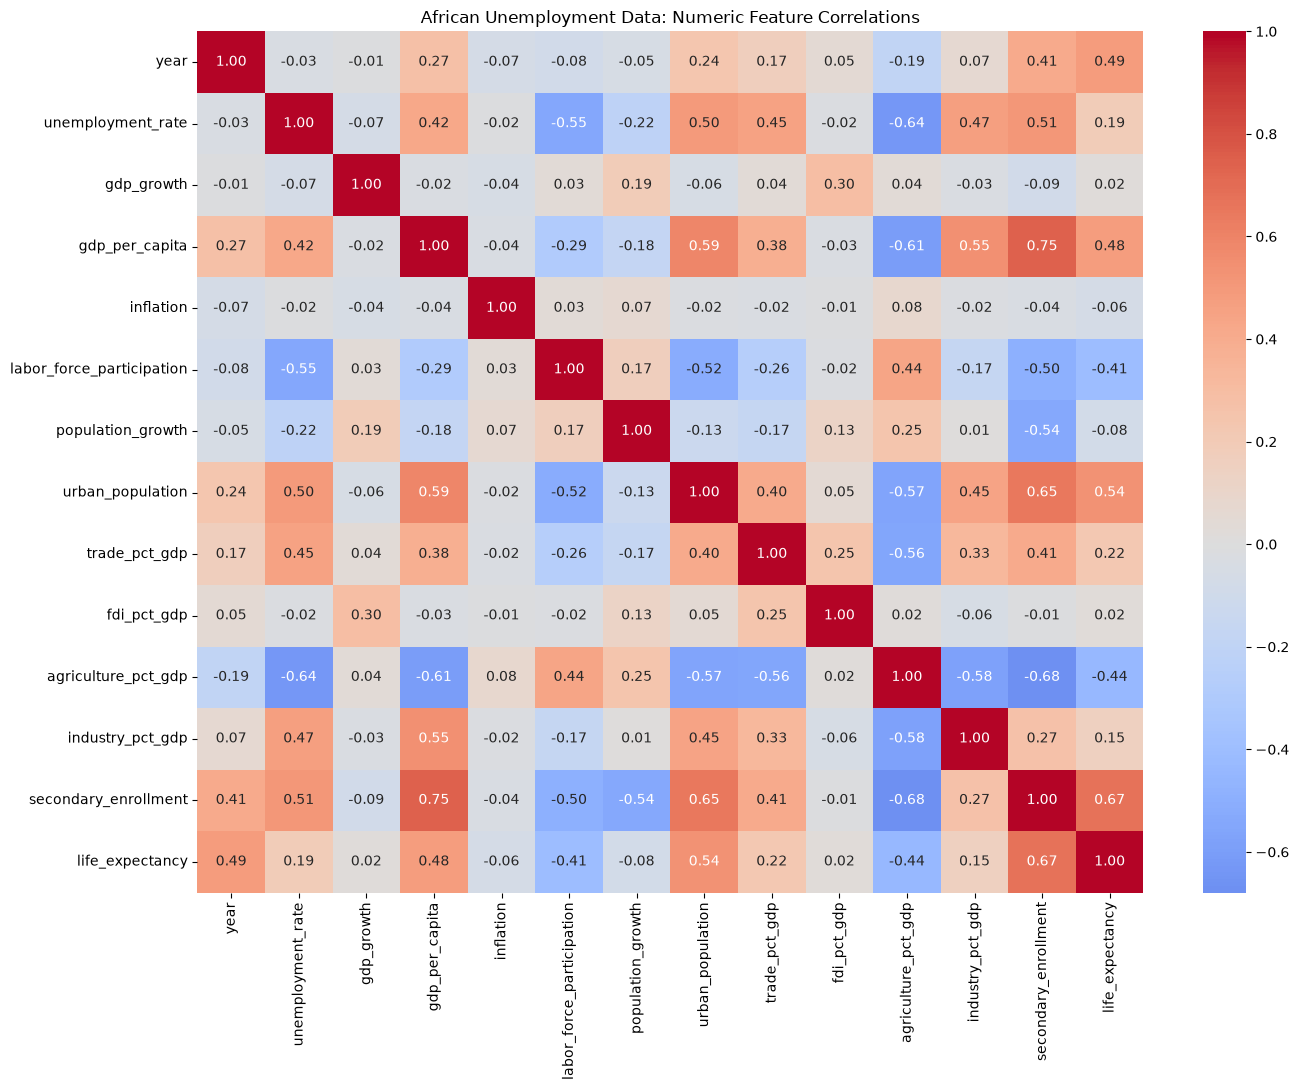

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = clean_df.select_dtypes(include="number").columns
plt.figure(figsize=(14, 11))
sns.heatmap(clean_df[numeric_columns].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("African Unemployment Data: Numeric Feature Correlations")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

Agriculture's share of GDP has the strongest negative link with unemployment (about -0.64). Labour-force participation also has a negative link (-0.55), while secondary school enrollment has a positive link (+0.51). These links help describe the data, but they do not prove that one factor causes unemployment, so I keep all the indicators for the models.

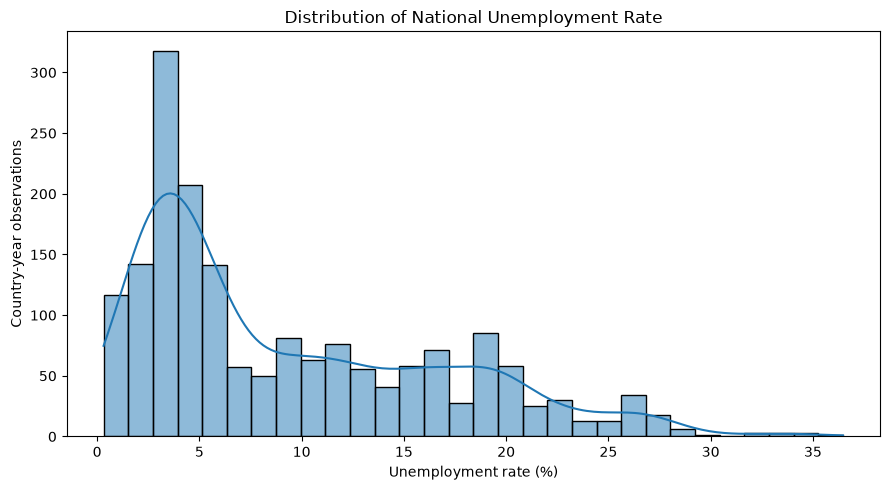

In [4]:
plt.figure(figsize=(9, 5))
sns.histplot(clean_df["unemployment_rate"], bins=30, kde=True)
plt.title("Distribution of National Unemployment Rate")
plt.xlabel("Unemployment rate (%)")
plt.ylabel("Country-year observations")
plt.tight_layout()
plt.savefig("unemployment_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

Unemployment rates are unevenly distributed: the median is about 5.95%, the average is 9.31%, and a smaller group of values reaches 36.47%. I keep these high values because they are part of the real data and should be included when testing the models.

Most correlated numeric features: ['agriculture_pct_gdp', 'labor_force_participation', 'secondary_enrollment']


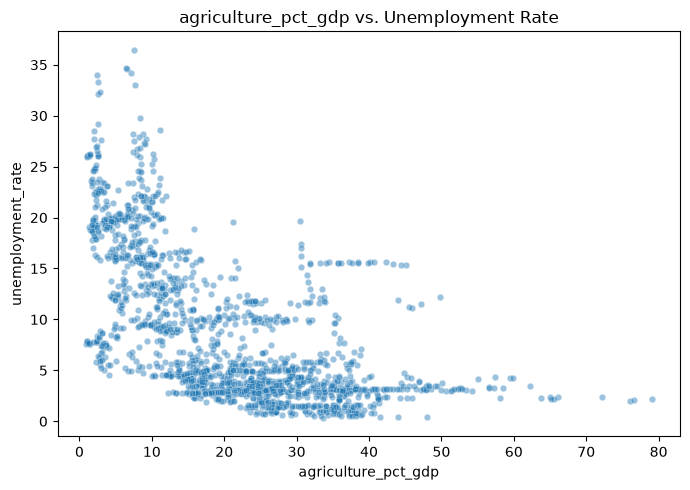

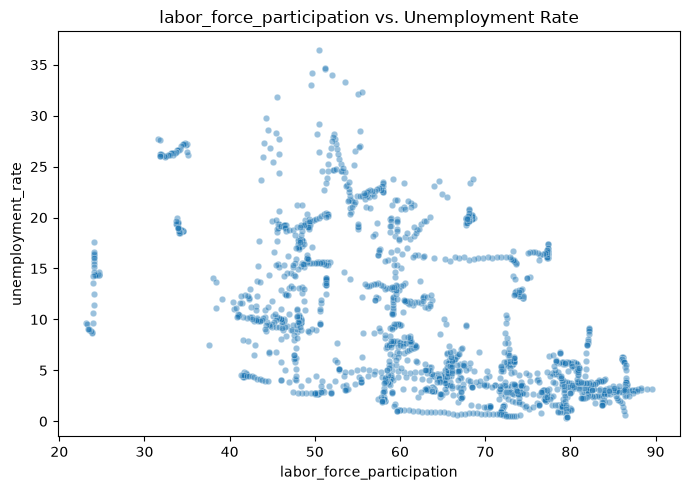

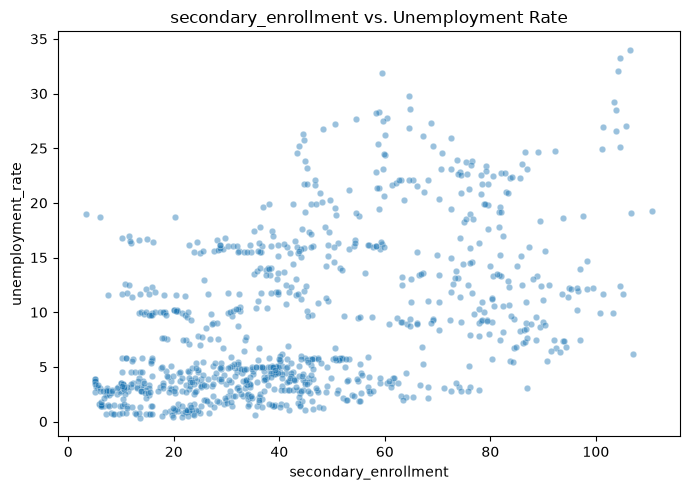

In [5]:
TARGET = "unemployment_rate"
correlations = clean_df.select_dtypes(include="number").corr()[TARGET].drop(TARGET).dropna()
top_correlated_features = correlations.abs().sort_values(ascending=False).head(3).index.tolist()
print("Most correlated numeric features:", top_correlated_features)
for feature in top_correlated_features:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=clean_df, x=feature, y=TARGET, alpha=0.45, s=22)
    plt.title(f"{feature} vs. Unemployment Rate")
    plt.tight_layout()
    safe_name = feature.replace("%", "pct").replace(" ", "_")
    plt.savefig(f"scatter_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()

Unemployment tends to be lower where agriculture's share of GDP and labour-force participation are higher, while the link with secondary enrollment is positive. The points are spread out, so no single feature explains the unemployment rate on its own. I keep all three features and let the models use them together with the other indicators.

# 5. Choose the model features

Each row already represents one country in one year, so I do not need a separate country-code feature. I use 13 numeric indicators and the categories `country` and `sub_region` as inputs; the unemployment rate is the value the model predicts. The correlation results show which numeric features have the strongest individual links with unemployment, but the models can also learn from several features together.

In [6]:
NUMERIC_FEATURES = [
    "year", "gdp_growth", "gdp_per_capita", "inflation",
    "labor_force_participation", "population_growth", "urban_population",
    "trade_pct_gdp", "fdi_pct_gdp", "agriculture_pct_gdp", "industry_pct_gdp",
    "secondary_enrollment", "life_expectancy",
]
CATEGORICAL_FEATURES = ["country", "sub_region"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "unemployment_rate"
print("Strongest numeric correlations with the target:")
display(correlations.abs().sort_values(ascending=False).head(5).rename("absolute_correlation").to_frame())
X = clean_df[FEATURE_COLUMNS]
y = clean_df[TARGET]

Strongest numeric correlations with the target:


,absolute_correlation
agriculture_pct_gdp,0.636265
labor_force_participation,0.547760
secondary_enrollment,0.512274
urban_population,0.496842
industry_pct_gdp,0.469424


# 6. Prepare the data and split it

I split the rows into training and test sets before fitting the preprocessing steps. For numeric columns, I fill missing values with the training-set median and scale the values. For country and sub-region, I fill missing values and use one-hot encoding. Because rows are split at random, the same country can appear in both sets, so the test score may be optimistic for a country the model has never seen.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, NUMERIC_FEATURES),
    ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES),
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (1439, 71)
Test shape: (360, 71)


# 7. Compare four regression models

I train all four scikit-learn models using the same training rows and compare them on the same test rows. I tune the `SGDRegressor` settings in the next section.

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor

models = {
    "SGDRegressor": SGDRegressor(max_iter=2000, tol=1e-4, random_state=42),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=250, random_state=42, n_jobs=-1
    ),
}
results = {}
for name, estimator in models.items():
    estimator.fit(X_train_processed, y_train)
    train_prediction = estimator.predict(X_train_processed)
    test_prediction = estimator.predict(X_test_processed)
    results[name] = {
        "model": estimator,
        "train_mse": mean_squared_error(y_train, train_prediction),
        "test_mse": mean_squared_error(y_test, test_prediction),
    }
print("Initial four-model evaluation complete.")

Initial four-model evaluation complete.


# 8. Tune SGDRegressor

I try different learning rates (`eta0`), regularization strengths (`alpha`), and numbers of training passes (epochs). For each setting, I train with `partial_fit` on shuffled training rows and measure MSE on the same test set.

In [9]:
from itertools import product
import numpy as np

TUNING_RATES = [0.00001, 0.0001, 0.0005]
TUNING_ALPHAS = [0.0001, 0.001]
TUNING_EPOCHS = [25, 75]
tuning_rows = []
tuning_models = []
rng = np.random.default_rng(42)
for eta0, alpha, epochs in product(TUNING_RATES, TUNING_ALPHAS, TUNING_EPOCHS):
    candidate = SGDRegressor(
        learning_rate="constant", eta0=eta0, alpha=alpha,
        random_state=42, tol=None,
    )
    for _ in range(epochs):
        order = rng.permutation(X_train_processed.shape[0])
        candidate.partial_fit(X_train_processed[order], y_train.iloc[order])
    train_mse = mean_squared_error(y_train, candidate.predict(X_train_processed))
    test_mse = mean_squared_error(y_test, candidate.predict(X_test_processed))
    tuning_rows.append({
        "eta0": eta0, "alpha": alpha, "epochs": epochs,
        "train_mse": train_mse, "test_mse": test_mse,
    })
    tuning_models.append(candidate)
best_original_index = min(range(len(tuning_rows)), key=lambda index: tuning_rows[index]["test_mse"])
tuning_table = pd.DataFrame(tuning_rows).sort_values("test_mse").reset_index(drop=True)
display(tuning_table)
best_tuning = tuning_table.iloc[0]
best_sgd = tuning_models[best_original_index]
results["SGDRegressor"] = {
    "model": best_sgd,
    "train_mse": float(best_tuning["train_mse"]),
    "test_mse": float(best_tuning["test_mse"]),
}
print("Selected SGD settings:", best_tuning.to_dict())

,eta0,alpha,epochs,train_mse,test_mse
0,0.00050,0.0001,75,5.550354,5.538498
1,0.00050,0.0010,75,5.657424,5.632832
2,0.00050,0.0001,25,10.732389,10.284530
3,0.00050,0.0010,25,10.821810,10.405065
4,0.00010,0.0001,75,15.622379,14.935018
5,0.00010,0.0010,75,15.705685,15.019413
6,0.00010,0.0001,25,37.220105,37.731853
7,0.00010,0.0010,25,37.279174,37.788119
8,0.00001,0.0001,75,77.003702,79.065878
9,0.00001,0.0010,75,77.020338,79.081627


Selected SGD settings: {'eta0': 0.0005, 'alpha': 0.0001, 'epochs': 75.0, 'train_mse': 5.550353515994016, 'test_mse': 5.538498276783468}


# 9. SGD loss curve

I start a new `SGDRegressor` and train it one epoch at a time. After each epoch, I calculate and save the training and test MSE so I can plot how the errors change.

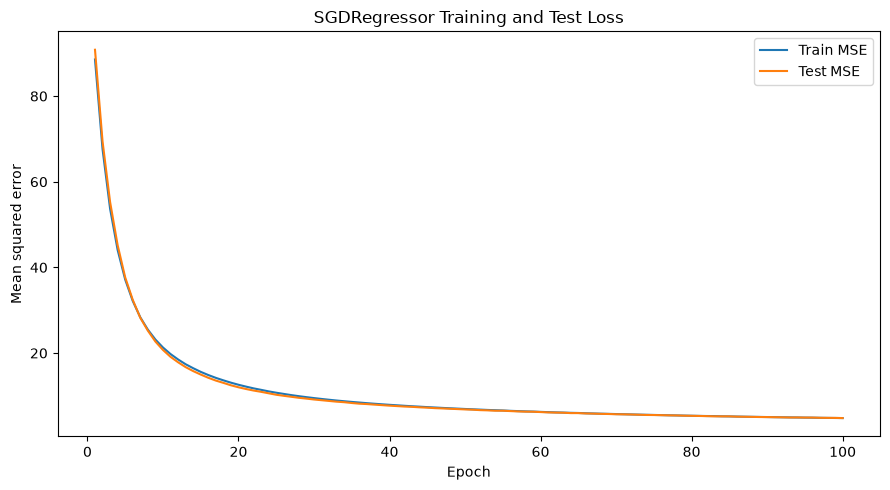

In [10]:
curve_model = SGDRegressor(
    learning_rate="constant", eta0=float(best_tuning["eta0"]),
    alpha=float(best_tuning["alpha"]), random_state=42, tol=None,
)
curve_train_mse = []
curve_test_mse = []
curve_rng = np.random.default_rng(42)
for _ in range(100):
    order = curve_rng.permutation(X_train_processed.shape[0])
    curve_model.partial_fit(X_train_processed[order], y_train.iloc[order])
    curve_train_mse.append(mean_squared_error(y_train, curve_model.predict(X_train_processed)))
    curve_test_mse.append(mean_squared_error(y_test, curve_model.predict(X_test_processed)))
plt.figure(figsize=(9, 5))
plt.plot(range(1, 101), curve_train_mse, label="Train MSE")
plt.plot(range(1, 101), curve_test_mse, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("SGDRegressor Training and Test Loss")
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()

The training and test MSE both fall from about 88 to about 5 over 100 epochs and stay close together. This suggests that SGD learns useful patterns without a large gap between training and test errors. I use the 75-epoch setting chosen in the tuning step for the model comparison.

# 10. Compare scatter plots before and after fitting a line

I use the numeric feature with the strongest link to unemployment in both plots. The second plot adds a straight line from a one-feature `LinearRegression` model.

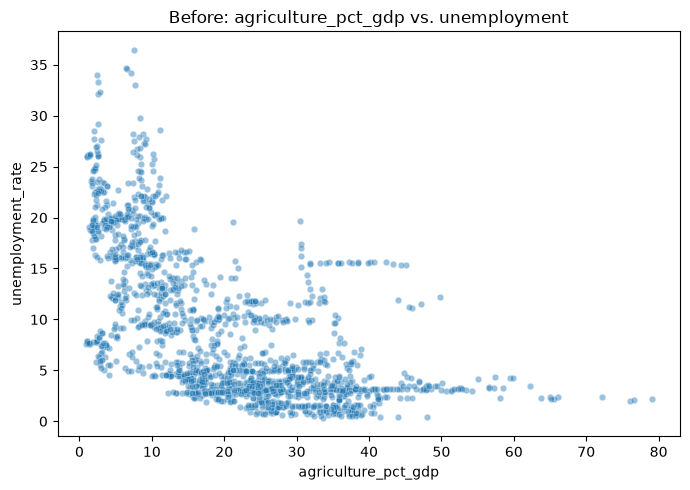

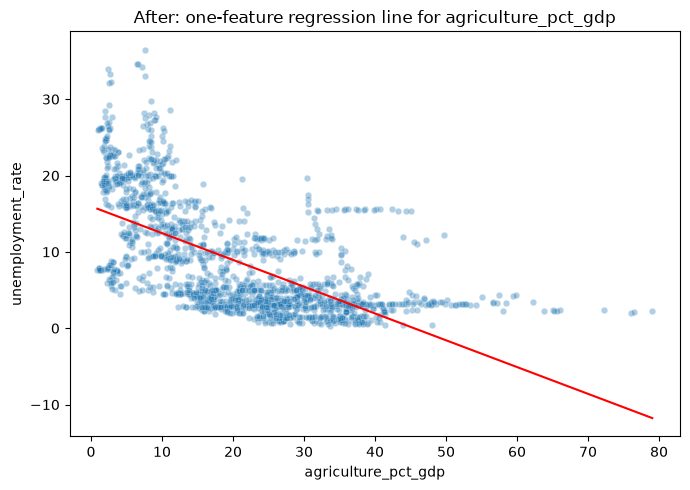

Single feature: agriculture_pct_gdp


In [11]:
from sklearn.linear_model import LinearRegression

single_feature = correlations.abs().idxmax()
scatter_data = clean_df[[single_feature, TARGET]].dropna()
plt.figure(figsize=(7, 5))
sns.scatterplot(data=scatter_data, x=single_feature, y=TARGET, alpha=0.45, s=22)
plt.title(f"Before: {single_feature} vs. unemployment")
plt.tight_layout()
plt.savefig("before_after_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

single_feature_model = LinearRegression().fit(scatter_data[[single_feature]], scatter_data[TARGET])
line_x = np.linspace(scatter_data[single_feature].min(), scatter_data[single_feature].max(), 200)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=scatter_data, x=single_feature, y=TARGET, alpha=0.35, s=22)
plt.plot(line_x, single_feature_model.predict(pd.DataFrame({single_feature: line_x})), color="red")
plt.title(f"After: one-feature regression line for {single_feature}")
plt.tight_layout()
plt.savefig("before_after_regression_line.png", dpi=160, bbox_inches="tight")
plt.show()
print("Single feature:", single_feature)

The first chart shows the data points without a fitted line. The second uses the same points and adds a straight line to show the average trend. This simple line does not show all country differences and does not prove that the feature causes unemployment.

# 11. Compare the models and choose one

In [12]:
comparison = pd.DataFrame({
    name: {"Train MSE": values["train_mse"], "Test MSE": values["test_mse"]}
    for name, values in results.items()
}).T.sort_values("Test MSE")
display(comparison)
best_model_name = comparison.index[0]
best_estimator = results[best_model_name]["model"]
print(f"Lowest test MSE: {best_model_name} ({comparison.loc[best_model_name, 'Test MSE']:.4f}).")

,Train MSE,Test MSE
RandomForestRegressor,0.159167,1.614583
DecisionTreeRegressor,0.000000,1.852620
LinearRegression,3.206582,3.114126
SGDRegressor,5.550354,5.538498


Lowest test MSE: RandomForestRegressor (1.6146).


I choose **RandomForestRegressor** because it has the lowest test MSE (**1.6146**) among the four models. A random forest can learn curved patterns and combinations of indicators. Its training error is much lower than its test error, which suggests some overfitting; the random country-year split also means the score may not show how well it works for a completely new country.

# 12. Save the best model and training data

I save the data-preparation steps and selected model together in one scikit-learn `Pipeline`. I also copy the cleaned training data to the API folder so the `/retrain` endpoint can use it.

In [13]:
import shutil

import joblib
from sklearn.pipeline import Pipeline

api_dir = Path("../API")
api_dir.mkdir(exist_ok=True)
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_estimator),
])
joblib.dump(best_pipeline, api_dir / "best_model.pkl")
shutil.copy2(DATA_DIR / "clean_unemployment_africa.csv", api_dir / "training_data.csv")
print("Saved:", api_dir / "best_model.pkl")
print("Copied:", api_dir / "training_data.csv")
print("Estimator:", best_model_name)

Saved: ..\API\best_model.pkl
Copied: ..\API\training_data.csv
Estimator: RandomForestRegressor


# 13. Predict one test row

This function loads the saved model, predicts unemployment for one row from the test set, and prints the predicted and actual values so I can compare them.

In [14]:
def predict_one_row(index):
    loaded_model = joblib.load(api_dir / "best_model.pkl")
    row = X_test.iloc[[index]]
    actual = float(y_test.iloc[index])
    predicted = float(loaded_model.predict(row)[0])
    print(f"Predicted unemployment rate: {predicted:.2f}%")
    print(f"Actual unemployment rate: {actual:.2f}%")


predict_one_row(0)

Predicted unemployment rate: 4.80%
Actual unemployment rate: 4.99%
